<a href="https://colab.research.google.com/github/aritra241013006124-commits/Aiml-3b/blob/main/Ailab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stroke Risk Prediction — Separate Output Cells

This version separates the work so that each model, metric result, confusion matrix, and graph has its **own output cell**.

Run the cells **from top to bottom**.

In [ ]:
# CELL 1 — Import libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.utils import resample

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# CELL 2 — Upload and load dataset

csv_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".csv")
]

if len(csv_files) == 0:
    print("Please select stroke_processed_5k.csv")
    uploaded = files.upload()
    csv_files = [f for f in uploaded.keys() if f.lower().endswith(".csv")]

if len(csv_files) == 0:
    raise ValueError("No CSV file was uploaded.")

if "stroke_processed_5k.csv" in csv_files:
    csv_file = "stroke_processed_5k.csv"
else:
    csv_file = csv_files[0]

df = pd.read_csv(os.path.join("/content", csv_file))

print("Dataset loaded successfully!")
print("File:", csv_file)
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File: stroke_processed_5k.csv
Shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


In [ ]:
# CELL 3 — Dataset information

print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset shape:", df.shape)

Columns:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Data types:
gender                 int64
age                  float64
hypertension           int64
heart_disease          int64
ever_married           int64
work_type              int64
Residence_type         int64
avg_glucose_level    float64
bmi                  float64
smoking_status         int64
stroke                 int64
dtype: object

Missing values:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

Dataset shape: (5110, 11)


Stroke target distribution:
stroke
0    4861
1     249
Name: count, dtype: int64

Percentage distribution:
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


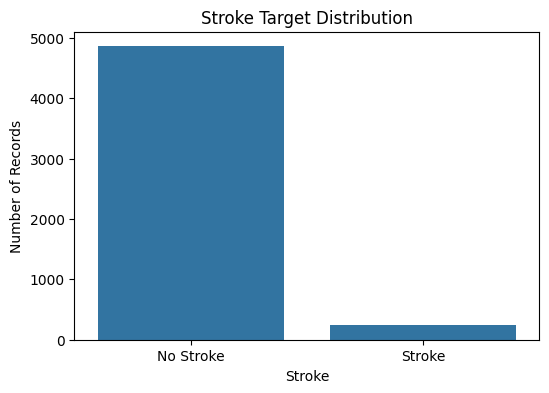

In [ ]:
# CELL 4 — Target distribution

print("Stroke target distribution:")
print(df["stroke"].value_counts())

print("\nPercentage distribution:")
print((df["stroke"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(x=df["stroke"])
plt.title("Stroke Target Distribution")
plt.xlabel("Stroke")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["No Stroke", "Stroke"])
plt.show()

In [ ]:
# CELL 5 — Prepare features and target

X = df.drop("stroke", axis=1)
y = df["stroke"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5110, 10)
Target shape: (5110,)


In [ ]:
# CELL 6 — Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (4088, 10)
Testing data : (1022, 10)

Training target distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing target distribution:
stroke
0    972
1     50
Name: count, dtype: int64


In [ ]:
# CELL 7 — Create balanced training data for KNN and ANN

train_data = pd.concat(
    [
        X_train.reset_index(drop=True),
        y_train.reset_index(drop=True).rename("stroke")
    ],
    axis=1
)

majority = train_data[train_data["stroke"] == 0]
minority = train_data[train_data["stroke"] == 1]

minority_upsampled = resample(
    minority,
    replace=True,
    n_samples=len(majority),
    random_state=42
)

balanced_train = pd.concat(
    [majority, minority_upsampled],
    axis=0
).sample(frac=1, random_state=42)

X_train_balanced = balanced_train.drop("stroke", axis=1)
y_train_balanced = balanced_train["stroke"]

print("Original training distribution:")
print(y_train.value_counts())

print("\nBalanced training distribution:")
print(y_train_balanced.value_counts())

Original training distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Balanced training distribution:
stroke
0    3889
1    3889
Name: count, dtype: int64


In [ ]:
# CELL 8 — Logistic Regression

model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])
model.fit(X_train, y_train)

y_pred_logistic_regression = model.predict(X_test)
y_prob_logistic_regression = model.predict_proba(X_test)[:, 1]

accuracy_logistic_regression = accuracy_score(y_test, y_pred_logistic_regression)
precision_logistic_regression = precision_score(y_test, y_pred_logistic_regression, zero_division=0)
recall_logistic_regression = recall_score(y_test, y_pred_logistic_regression, zero_division=0)
f1_logistic_regression = f1_score(y_test, y_pred_logistic_regression, zero_division=0)
auc_logistic_regression = roc_auc_score(y_test, y_prob_logistic_regression)

fpr_logistic_regression, tpr_logistic_regression, _ = roc_curve(y_test, y_prob_logistic_regression)
cm_logistic_regression = confusion_matrix(y_test, y_pred_logistic_regression)

print("Logistic Regression")
print("-" * 40)
print(f"Accuracy : {accuracy_logistic_regression:.4f}")
print(f"Precision: {precision_logistic_regression:.4f}")
print(f"Recall   : {recall_logistic_regression:.4f}")
print(f"F1-Score : {f1_logistic_regression:.4f}")
print(f"AUC      : {auc_logistic_regression:.4f}")

Logistic Regression
----------------------------------------
Accuracy : 0.7515
Precision: 0.1408
Recall   : 0.8000
F1-Score : 0.2395
AUC      : 0.8387


In [ ]:
# CELL 9 — Decision Tree

model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)
model.fit(X_train, y_train)

y_pred_decision_tree = model.predict(X_test)
y_prob_decision_tree = model.predict_proba(X_test)[:, 1]

accuracy_decision_tree = accuracy_score(y_test, y_pred_decision_tree)
precision_decision_tree = precision_score(y_test, y_pred_decision_tree, zero_division=0)
recall_decision_tree = recall_score(y_test, y_pred_decision_tree, zero_division=0)
f1_decision_tree = f1_score(y_test, y_pred_decision_tree, zero_division=0)
auc_decision_tree = roc_auc_score(y_test, y_prob_decision_tree)

fpr_decision_tree, tpr_decision_tree, _ = roc_curve(y_test, y_prob_decision_tree)
cm_decision_tree = confusion_matrix(y_test, y_pred_decision_tree)

print("Decision Tree")
print("-" * 40)
print(f"Accuracy : {accuracy_decision_tree:.4f}")
print(f"Precision: {precision_decision_tree:.4f}")
print(f"Recall   : {recall_decision_tree:.4f}")
print(f"F1-Score : {f1_decision_tree:.4f}")
print(f"AUC      : {auc_decision_tree:.4f}")

Decision Tree
----------------------------------------
Accuracy : 0.7456
Precision: 0.1168
Recall   : 0.6400
F1-Score : 0.1975
AUC      : 0.7285


In [ ]:
# CELL 10 — Random Forest

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

y_pred_random_forest = model.predict(X_test)
y_prob_random_forest = model.predict_proba(X_test)[:, 1]

accuracy_random_forest = accuracy_score(y_test, y_pred_random_forest)
precision_random_forest = precision_score(y_test, y_pred_random_forest, zero_division=0)
recall_random_forest = recall_score(y_test, y_pred_random_forest, zero_division=0)
f1_random_forest = f1_score(y_test, y_pred_random_forest, zero_division=0)
auc_random_forest = roc_auc_score(y_test, y_prob_random_forest)

fpr_random_forest, tpr_random_forest, _ = roc_curve(y_test, y_prob_random_forest)
cm_random_forest = confusion_matrix(y_test, y_pred_random_forest)

print("Random Forest")
print("-" * 40)
print(f"Accuracy : {accuracy_random_forest:.4f}")
print(f"Precision: {precision_random_forest:.4f}")
print(f"Recall   : {recall_random_forest:.4f}")
print(f"F1-Score : {f1_random_forest:.4f}")
print(f"AUC      : {auc_random_forest:.4f}")

Random Forest
----------------------------------------
Accuracy : 0.9286
Precision: 0.2830
Recall   : 0.3000
F1-Score : 0.2913
AUC      : 0.8350


In [ ]:
# CELL 11 — SVM

model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        C=1.0,
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=42
    ))
])
model.fit(X_train, y_train)

y_pred_svm = model.predict(X_test)
y_prob_svm = model.predict_proba(X_test)[:, 1]

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, zero_division=0)
recall_svm = recall_score(y_test, y_pred_svm, zero_division=0)
f1_svm = f1_score(y_test, y_pred_svm, zero_division=0)
auc_svm = roc_auc_score(y_test, y_prob_svm)

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
cm_svm = confusion_matrix(y_test, y_pred_svm)

print("SVM")
print("-" * 40)
print(f"Accuracy : {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall   : {recall_svm:.4f}")
print(f"F1-Score : {f1_svm:.4f}")
print(f"AUC      : {auc_svm:.4f}")

SVM
----------------------------------------
Accuracy : 0.7358
Precision: 0.1181
Recall   : 0.6800
F1-Score : 0.2012
AUC      : 0.7856


In [ ]:
# CELL 12 — KNN

model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    ))
])
model.fit(X_train_balanced, y_train_balanced)

y_pred_knn = model.predict(X_test)
y_prob_knn = model.predict_proba(X_test)[:, 1]

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, zero_division=0)
recall_knn = recall_score(y_test, y_pred_knn, zero_division=0)
f1_knn = f1_score(y_test, y_pred_knn, zero_division=0)
auc_knn = roc_auc_score(y_test, y_prob_knn)

fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
cm_knn = confusion_matrix(y_test, y_pred_knn)

print("KNN")
print("-" * 40)
print(f"Accuracy : {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall   : {recall_knn:.4f}")
print(f"F1-Score : {f1_knn:.4f}")
print(f"AUC      : {auc_knn:.4f}")

KNN
----------------------------------------
Accuracy : 0.8288
Precision: 0.0805
Recall   : 0.2400
F1-Score : 0.1206
AUC      : 0.6183


In [ ]:
# CELL 13 — ANN

model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.001,
        max_iter=1500,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=42
    ))
])
model.fit(X_train_balanced, y_train_balanced)

y_pred_ann = model.predict(X_test)
y_prob_ann = model.predict_proba(X_test)[:, 1]

accuracy_ann = accuracy_score(y_test, y_pred_ann)
precision_ann = precision_score(y_test, y_pred_ann, zero_division=0)
recall_ann = recall_score(y_test, y_pred_ann, zero_division=0)
f1_ann = f1_score(y_test, y_pred_ann, zero_division=0)
auc_ann = roc_auc_score(y_test, y_prob_ann)

fpr_ann, tpr_ann, _ = roc_curve(y_test, y_prob_ann)
cm_ann = confusion_matrix(y_test, y_pred_ann)

print("ANN")
print("-" * 40)
print(f"Accuracy : {accuracy_ann:.4f}")
print(f"Precision: {precision_ann:.4f}")
print(f"Recall   : {recall_ann:.4f}")
print(f"F1-Score : {f1_ann:.4f}")
print(f"AUC      : {auc_ann:.4f}")

ANN
----------------------------------------
Accuracy : 0.8728
Precision: 0.1429
Recall   : 0.3200
F1-Score : 0.1975
AUC      : 0.7620


In [ ]:
# CELL 14 — Performance comparison table

results_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_logistic_regression,
        "Precision": precision_logistic_regression,
        "Recall": recall_logistic_regression,
        "F1-Score": f1_logistic_regression,
        "AUC": auc_logistic_regression
    },
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_decision_tree,
        "Precision": precision_decision_tree,
        "Recall": recall_decision_tree,
        "F1-Score": f1_decision_tree,
        "AUC": auc_decision_tree
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_random_forest,
        "Precision": precision_random_forest,
        "Recall": recall_random_forest,
        "F1-Score": f1_random_forest,
        "AUC": auc_random_forest
    },
    {
        "Model": "SVM",
        "Accuracy": accuracy_svm,
        "Precision": precision_svm,
        "Recall": recall_svm,
        "F1-Score": f1_svm,
        "AUC": auc_svm
    },
    {
        "Model": "KNN",
        "Accuracy": accuracy_knn,
        "Precision": precision_knn,
        "Recall": recall_knn,
        "F1-Score": f1_knn,
        "AUC": auc_knn
    },
    {
        "Model": "ANN",
        "Accuracy": accuracy_ann,
        "Precision": precision_ann,
        "Recall": recall_ann,
        "F1-Score": f1_ann,
        "AUC": auc_ann
    }
])

results_df = results_df.sort_values(
    by=["F1-Score", "AUC"],
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,AUC
0,Random Forest,0.9286,0.2830,0.30,0.2913,0.8350
1,Logistic Regression,0.7515,0.1408,0.80,0.2395,0.8387
2,SVM,0.7358,0.1181,0.68,0.2012,0.7856
3,ANN,0.8728,0.1429,0.32,0.1975,0.7620
4,Decision Tree,0.7456,0.1168,0.64,0.1975,0.7285
5,KNN,0.8288,0.0805,0.24,0.1206,0.6183


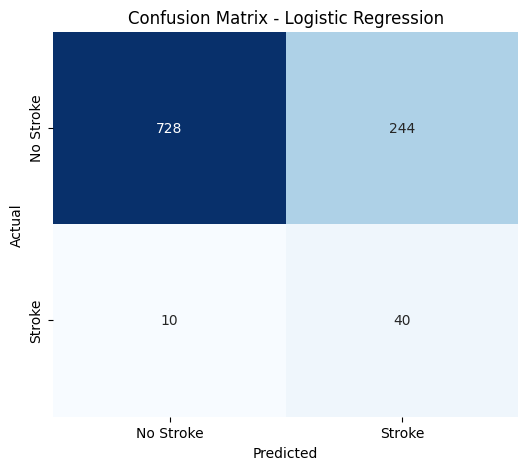

In [ ]:
# CELL 15 — Confusion Matrix: Logistic Regression

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_logistic_regression,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Stroke", "Stroke"],
    yticklabels=["No Stroke", "Stroke"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

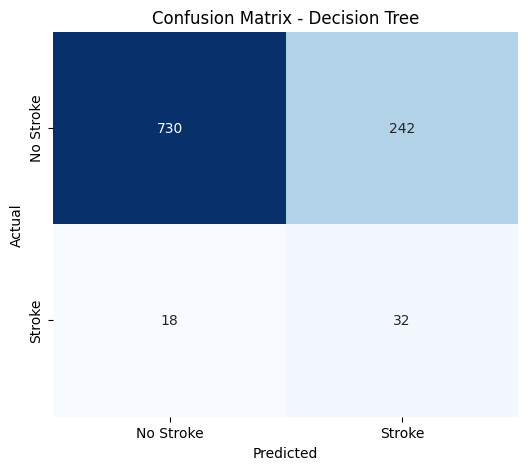

In [ ]:
# CELL 16 — Confusion Matrix: Decision Tree

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_decision_tree,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Stroke", "Stroke"],
    yticklabels=["No Stroke", "Stroke"]
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

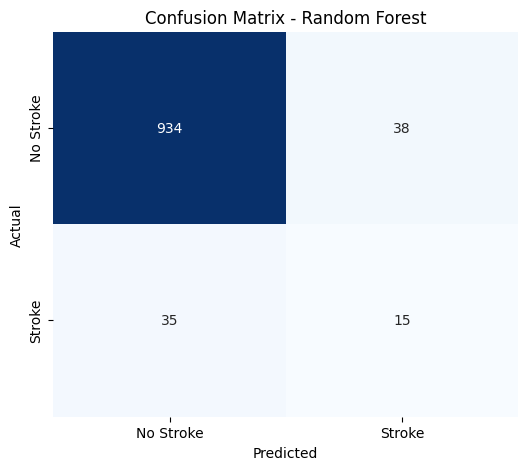

In [ ]:
# CELL 17 — Confusion Matrix: Random Forest

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_random_forest,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Stroke", "Stroke"],
    yticklabels=["No Stroke", "Stroke"]
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

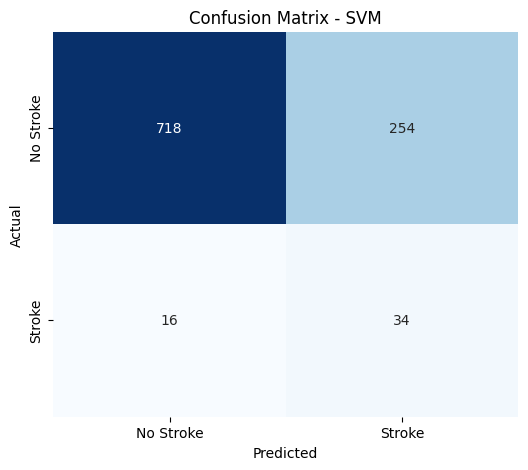

In [ ]:
# CELL 18 — Confusion Matrix: SVM

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Stroke", "Stroke"],
    yticklabels=["No Stroke", "Stroke"]
)

plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

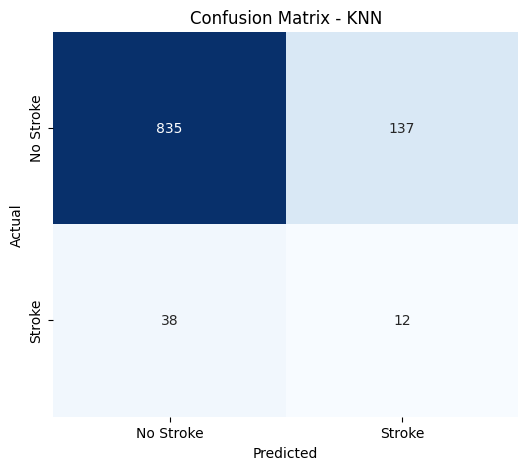

In [ ]:
# CELL 19 — Confusion Matrix: KNN

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Stroke", "Stroke"],
    yticklabels=["No Stroke", "Stroke"]
)

plt.title("Confusion Matrix - KNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

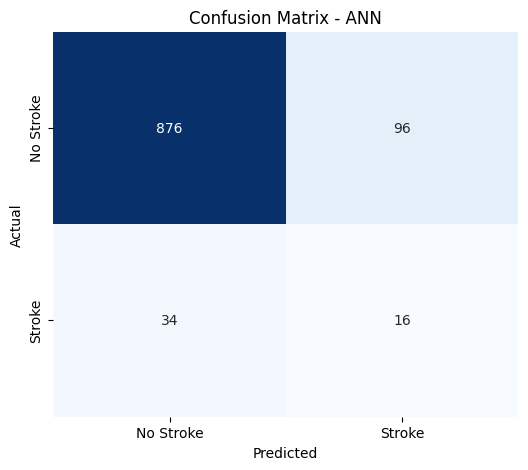

In [ ]:
# CELL 20 — Confusion Matrix: ANN

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_ann,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Stroke", "Stroke"],
    yticklabels=["No Stroke", "Stroke"]
)

plt.title("Confusion Matrix - ANN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

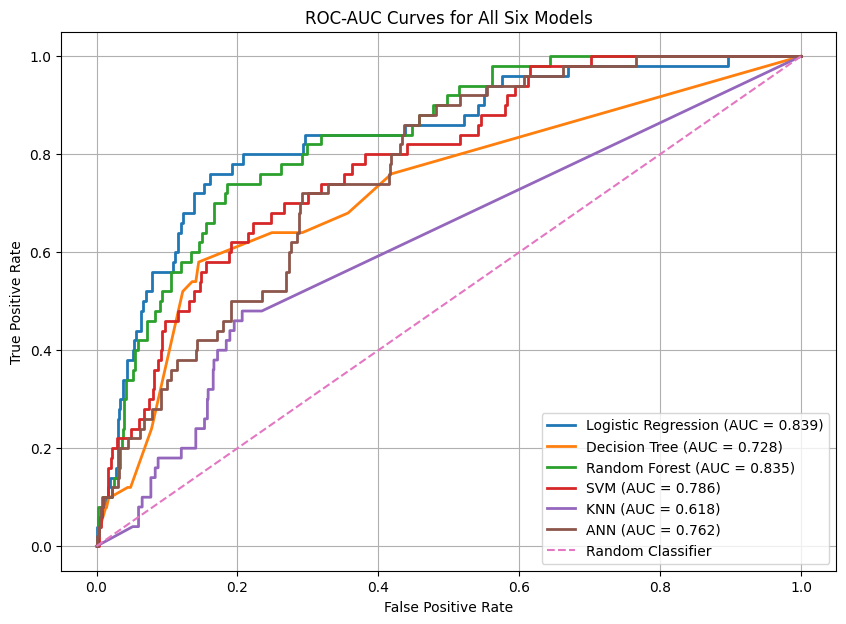

In [ ]:
# CELL 21 — Combined ROC-AUC curve for all six models

plt.figure(figsize=(10, 7))

roc_items = [
    ("Logistic Regression", fpr_logistic_regression, tpr_logistic_regression, auc_logistic_regression),
    ("Decision Tree", fpr_decision_tree, tpr_decision_tree, auc_decision_tree),
    ("Random Forest", fpr_random_forest, tpr_random_forest, auc_random_forest),
    ("SVM", fpr_svm, tpr_svm, auc_svm),
    ("KNN", fpr_knn, tpr_knn, auc_knn),
    ("ANN", fpr_ann, tpr_ann, auc_ann)
]

for name, fpr, tpr, auc_value in roc_items:
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curves for All Six Models")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# CELL 22 — Top 3 models

top_3 = results_df.head(3).copy()

print("Top 3 Models for Stroke Risk Prediction Analysis")
display(top_3.round(4))

Top 3 Models for Stroke Risk Prediction Analysis


,Model,Accuracy,Precision,Recall,F1-Score,AUC
0,Random Forest,0.9286,0.2830,0.30,0.2913,0.8350
1,Logistic Regression,0.7515,0.1408,0.80,0.2395,0.8387
2,SVM,0.7358,0.1181,0.68,0.2012,0.7856


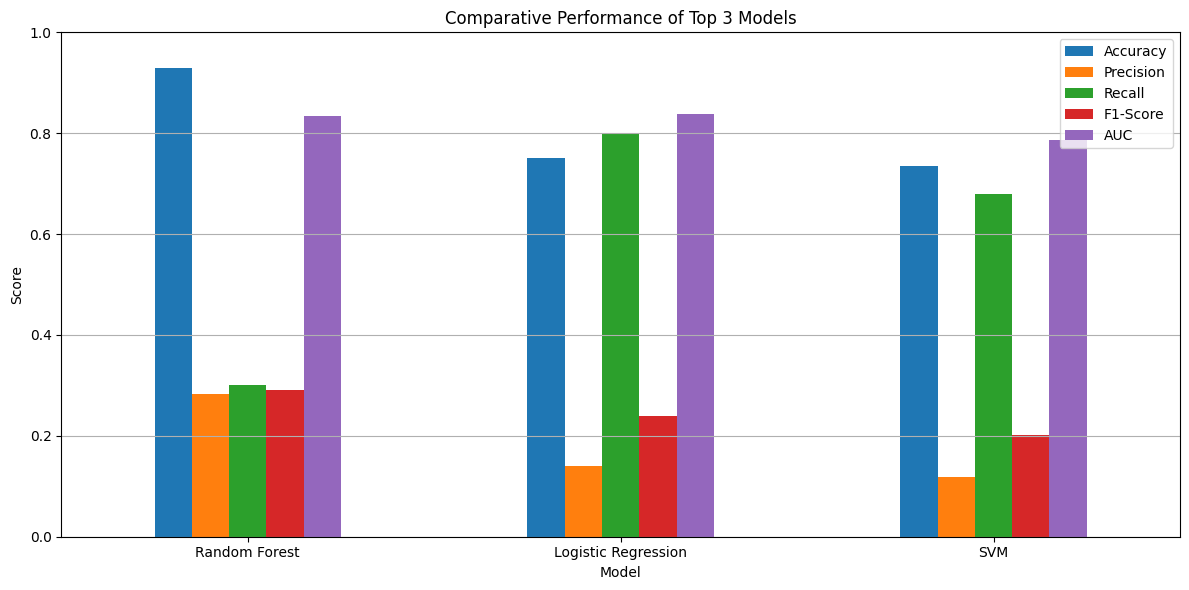

In [ ]:
# CELL 23 — Top 3 comparison bar chart

top_3_plot = top_3.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "AUC"]
]

ax = top_3_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Comparative Performance of Top 3 Models")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

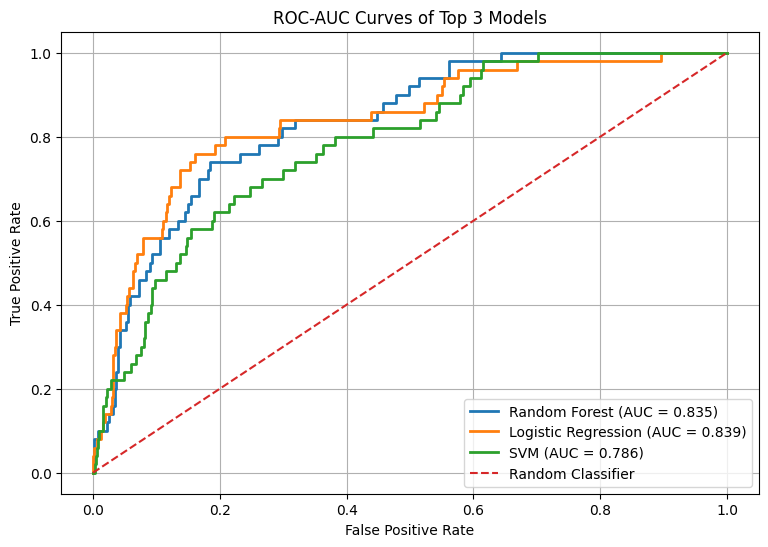

In [ ]:
# CELL 24 — ROC-AUC curves for Top 3 models

roc_lookup = {
    "Logistic Regression": (fpr_logistic_regression, tpr_logistic_regression, auc_logistic_regression),
    "Decision Tree": (fpr_decision_tree, tpr_decision_tree, auc_decision_tree),
    "Random Forest": (fpr_random_forest, tpr_random_forest, auc_random_forest),
    "SVM": (fpr_svm, tpr_svm, auc_svm),
    "KNN": (fpr_knn, tpr_knn, auc_knn),
    "ANN": (fpr_ann, tpr_ann, auc_ann)
}

plt.figure(figsize=(9, 6))

for name in top_3["Model"]:
    fpr, tpr, auc_value = roc_lookup[name]
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curves of Top 3 Models")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# CELL 25 — Final Top 3 summary

print("=" * 70)
print("FINAL TOP 3 MODEL COMPARISON FOR STROKE RISK PREDICTION")
print("=" * 70)

for rank, (_, row) in enumerate(top_3.iterrows(), start=1):
    print(f"\nRank {rank}: {row['Model']}")
    print(f"Accuracy : {row['Accuracy']:.4f}")
    print(f"Precision: {row['Precision']:.4f}")
    print(f"Recall   : {row['Recall']:.4f}")
    print(f"F1-Score : {row['F1-Score']:.4f}")
    print(f"AUC      : {row['AUC']:.4f}")

FINAL TOP 3 MODEL COMPARISON FOR STROKE RISK PREDICTION

Rank 1: Random Forest
Accuracy : 0.9286
Precision: 0.2830
Recall   : 0.3000
F1-Score : 0.2913
AUC      : 0.8350

Rank 2: Logistic Regression
Accuracy : 0.7515
Precision: 0.1408
Recall   : 0.8000
F1-Score : 0.2395
AUC      : 0.8387

Rank 3: SVM
Accuracy : 0.7358
Precision: 0.1181
Recall   : 0.6800
F1-Score : 0.2012
AUC      : 0.7856


## Screenshot-friendly output order

For the lab record, the important outputs are:

1. Dataset information
2. Target distribution
3. Train/test split
4. Each model's individual performance
5. Overall comparison table
6. Six individual confusion matrices
7. Combined ROC-AUC graph
8. Top-3 table
9. Top-3 comparison bar chart
10. Top-3 ROC-AUC graph
11. Final Top-3 summary